In [2]:
%pip install -q landingai opencv-python pillow matplotlib pandas

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tifffil

In [3]:
%pip install --no-cache-dir --force-reinstall numpy==2.2.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 144.9 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires numpy<2.0.0,>=1.21.0, but you have numpy 2.2.6 which is incompatible.


In [4]:
%pip install -q landingai opencv-python pillow matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.2 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tifffile 2026.10.15 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
shap 0.54.1 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
dm-tree 0.1.10 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatib

In [2]:
import cv2
import os
import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw
from collections import Counter
from google.colab import files
from IPython.display import display
from landingai.predict import Predictor

API_KEY = getpass.getpass("Enter your LandingAI API key: ")

ENDPOINT_ID = "7f7bb54c-7726-418a-9078-3de330578398"

predictor = Predictor(ENDPOINT_ID, api_key=API_KEY)

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Visual Interview Coach initialized.")

Enter your LandingAI API key: ··········
Visual Interview Coach initialized.


In [3]:
uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Could not open video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps if fps > 0 else 0

print("Video:", video_path)
print("Duration:", round(duration, 2), "seconds")
print("FPS:", fps)

Saving 7644024-uhd_2160_4096_25fps.mp4 to 7644024-uhd_2160_4096_25fps.mp4
Video: 7644024-uhd_2160_4096_25fps.mp4
Duration: 16.6 seconds
FPS: 25.0


In [5]:
def detect_faces(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(48, 48)
    )

    return faces


def classify_expression(face_crop):
    rgb_face = cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB)
    pil_face = Image.fromarray(rgb_face)

    predictions = predictor.predict(pil_face)

    if not predictions:
        return "Unknown", 0.0

    best = max(predictions, key=lambda p: p.score)

    return best.label_name, float(best.score)

In [6]:
results = []
annotated_frames = []

sample_interval = max(1, int(fps))  # Approximately one frame per second

frame_number = 0

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

while True:
    success, frame = cap.read()

    if not success:
        break

    if frame_number % sample_interval == 0:

        timestamp = frame_number / fps if fps > 0 else 0
        faces = detect_faces(frame)

        frame_results = []

        for (x, y, w, h) in faces:

            face_crop = frame[y:y+h, x:x+w]

            if face_crop.size == 0:
                continue

            try:
                label, confidence = classify_expression(face_crop)

                results.append({
                    "Timestamp": round(timestamp, 2),
                    "Expression": label,
                    "Confidence": round(confidence, 3)
                })

                frame_results.append(label)

                text = f"{label}: {confidence:.2f}"

                cv2.rectangle(
                    frame, (x, y), (x+w, y+h), (0, 255, 0), 2
                )

                cv2.putText(
                    frame, text, (x, y-10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (0, 255, 0), 2
                )

            except Exception as e:
                print("Inference error:", e)

        if len(annotated_frames) < 10:
            annotated_frames.append(
                cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            )

    frame_number += 1

cap.release()

df = pd.DataFrame(results)

if df.empty:
    print("No faces or expressions detected.")
else:
    print("Video analysis completed.")
    display(df.head(20))

Video analysis completed.


,Timestamp,Expression,Confidence
0,0.0,neutral,0.657
1,1.0,disgust,0.294
2,2.0,neutral,0.420
3,3.0,neutral,0.477
4,4.0,neutral,0.287
5,7.0,angry,0.281
6,8.0,neutral,0.523
7,9.0,neutral,0.451
8,10.0,neutral,0.490
9,11.0,neutral,0.319


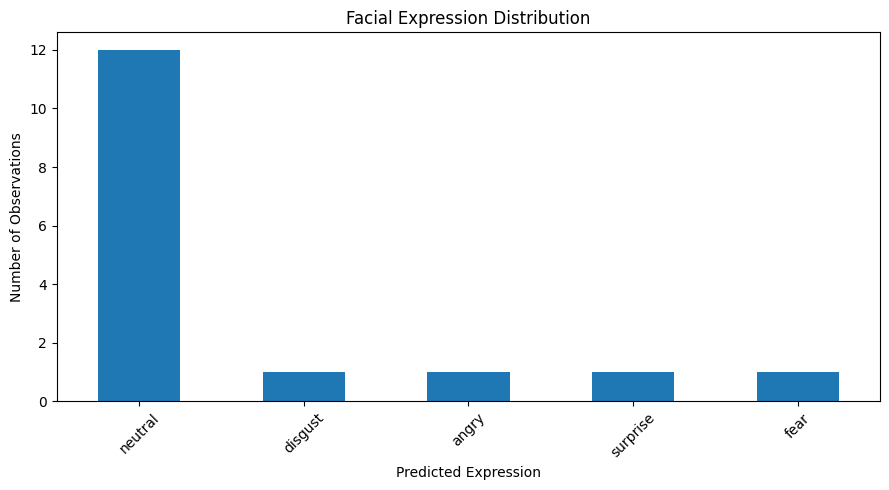


Expression Summary
Expression
neutral     12
disgust      1
angry        1
surprise     1
fear         1
Name: count, dtype: int64

Average Confidence: 0.388


In [7]:
if not df.empty:

    expression_counts = df["Expression"].value_counts()

    plt.figure(figsize=(9, 5))
    expression_counts.plot(kind="bar")

    plt.title("Facial Expression Distribution")
    plt.xlabel("Predicted Expression")
    plt.ylabel("Number of Observations")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print("\nExpression Summary")
    print(expression_counts)

    print("\nAverage Confidence:",
          round(df["Confidence"].mean(), 3))

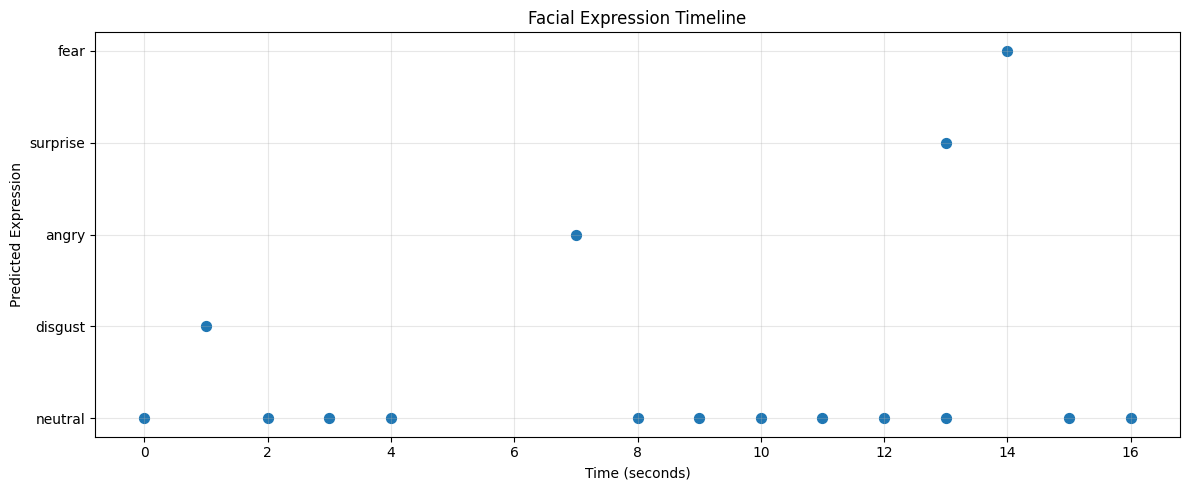

In [8]:
if not df.empty:

    plt.figure(figsize=(12, 5))

    plt.scatter(
        df["Timestamp"],
        df["Expression"],
        s=50
    )

    plt.title("Facial Expression Timeline")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Predicted Expression")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [9]:
def generate_feedback(df):

    counts = df["Expression"].value_counts()
    total = len(df)

    dominant_expression = counts.idxmax()
    dominant_percentage = (counts.max() / total) * 100

    print("=" * 50)
    print("VISUAL INTERVIEW COACH REPORT")
    print("=" * 50)

    print(f"\nTotal observations: {total}")

    print(
        f"Most frequent expression prediction: "
        f"{dominant_expression}"
    )

    print(
        f"Frequency: {dominant_percentage:.1f}%"
    )

    print("\nObservations:")

    if dominant_expression.lower() in ["happy", "happiness", "joy"]:
        print("- Smiling expressions appeared frequently.")

    elif dominant_expression.lower() in ["sad", "sadness"]:
        print("- Sad facial expressions were frequently predicted.")

    elif dominant_expression.lower() in ["angry", "anger"]:
        print("- Angry facial expressions were frequently predicted.")

    elif dominant_expression.lower() in ["neutral", "calm"]:
        print("- Neutral facial expressions appeared frequently.")

    else:
        print("- Multiple facial-expression patterns were observed.")

    print("\nSuggestions:")
    print("- Practise maintaining a natural on-camera expression.")
    print("- Review your interview recording.")
    print("- Focus on clear speech and structured answers.")

    print("\nNote: These are facial-expression predictions,")
    print("not measurements of actual emotions or confidence.")


if not df.empty:
    generate_feedback(df)

VISUAL INTERVIEW COACH REPORT

Total observations: 16
Most frequent expression prediction: neutral
Frequency: 75.0%

Observations:
- Neutral facial expressions appeared frequently.

Suggestions:
- Practise maintaining a natural on-camera expression.
- Review your interview recording.
- Focus on clear speech and structured answers.

Note: These are facial-expression predictions,
not measurements of actual emotions or confidence.


In [10]:
if not df.empty:

    df.to_csv("interview_expression_report.csv", index=False)

    print("Report saved successfully.")

    files.download("interview_expression_report.csv")

Report saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>